# 04 · Lateness vs. repeat purchase

**Question:** Are customers whose first order arrived late less likely to buy
again within 180 days?

Source: the `order_outcomes` view (`sql/02_order_outcomes.sql`).
- One row per customer: their **first order** only.
- **Repeat** = another order at least 1 day later, within 180 days.
- Only customers whose 180-day window ends before the data does
  (first order before ~Mar 2018), so no one is wrongly counted as "did not return".

Repeat purchase is rare (~3%), so expect wider confidence intervals than for reviews.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.formula.api as smf

# Notebooks run from notebooks/, so add src/ to the import path.
sys.path.insert(0, str(Path.cwd().parent / "src"))
from db import query

sns.set_theme(style="whitegrid")

In [2]:
from statsmodels.stats.proportion import proportion_confint

customers = query("""
    SELECT customer_unique_id, is_late, days_late, review_score,
           repeat_within_180d::int AS repeated,
           customer_state, purchase_month::text AS purchase_month
    FROM order_outcomes
    WHERE is_first_order
      AND repeat_within_180d IS NOT NULL
""")
print(f"{len(customers):,} customers, {customers['repeated'].sum():,} came back within 180 days")


def repeat_rate(df, by):
    """Repeat rate (%) per group with a 95% Wilson confidence interval."""
    out = df.groupby(by, observed=True)["repeated"].agg(customers="count", repeats="sum")
    low, high = proportion_confint(out["repeats"], out["customers"], method="wilson")
    out["repeat_pct"] = 100 * out["repeats"] / out["customers"]
    out["ci_low"], out["ci_high"] = 100 * low, 100 * high
    return out.round(2)

56,123 customers, 1,110 came back within 180 days


## 1. Late vs. on-time first order

**Question:** What share of customers came back within 180 days, depending on
whether their first order was late?

In [3]:
by_late = repeat_rate(customers, "is_late")
by_late

,customers,repeats,repeat_pct,ci_low,ci_high
is_late,,,,,
False,52202,1048,2.01,1.89,2.13
True,3921,62,1.58,1.24,2.02


**Observations:**

- Only 2.0% of customers came back within 180 days (1,110 of 56,123), so repeat purchase is rare.
- Late first order: 1.58% came back vs 2.01% for on-time, a gap of −0.43 percentage points (about 21% lower; 1.58 / 2.01 ≈ 0.79).
- The 95% CIs slightly overlap (late 1.24–2.02, on-time 1.89–2.13), so this gap may be noise.
- Only 62 late customers came back, which is why the late CI is wide.

## 2. Repeat rate by days late

**Question:** Does the chance of returning drop gradually with lateness, or
only past a certain point? Groups are wider than in notebook 03 because
repeats are rare.

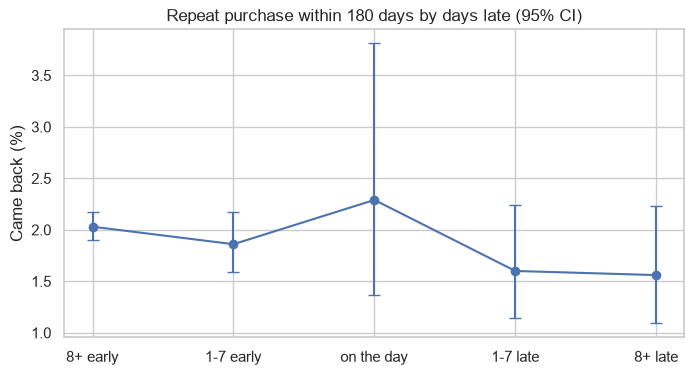

,customers,repeats,repeat_pct,ci_low,ci_high
days_late_group,,,,,
8+ early,43298,880,2.03,1.90,2.17
1-7 early,8293,154,1.86,1.59,2.17
on the day,611,14,2.29,1.37,3.81
1-7 late,2062,33,1.60,1.14,2.24
8+ late,1859,29,1.56,1.09,2.23


In [4]:
bins   = [-np.inf, -8, -1, 0, 7, np.inf]
labels = ["8+ early", "1-7 early", "on the day", "1-7 late", "8+ late"]
customers["days_late_group"] = pd.cut(customers["days_late"], bins=bins, labels=labels)

by_days = repeat_rate(customers, "days_late_group")

fig, ax = plt.subplots(figsize=(8, 4))
ax.errorbar(by_days.index.astype(str), by_days["repeat_pct"],
            yerr=[by_days["repeat_pct"] - by_days["ci_low"], by_days["ci_high"] - by_days["repeat_pct"]],
            marker="o", capsize=4)
ax.set(title="Repeat purchase within 180 days by days late (95% CI)", xlabel="", ylabel="Came back (%)")
plt.show()
by_days

**Observations:**

- Late groups come back a bit less (1.60% at 1–7 late, 1.56% at 8+ late) than 8+ early (2.03%).
- All the CIs overlap, so there is no clear drop with lateness and no clear break at the promised date.
- "On the day" (2.29%) is the highest, but it is tiny (611 customers, 14 repeats, CI 1.37–3.81). Likely noise.

## 3. Adjusted for state and month

**Why adjust:** notebook 02 showed late orders are concentrated in some
**states** (Northeast) and **months** (Nov 2017, Feb-Mar 2018). If those
states or months differ in this outcome anyway, the simple comparison above
mixes that in with the effect of lateness.

The regression below compares late and on-time orders **within the same
state and purchase month**. `is_late` is the number to read: the difference
associated with being late after that adjustment. `HC1` gives robust
standard errors (no assumption that the spread is equal across groups).

This is still an **association, not proof of cause**: anything else that
differs between late and on-time orders (product type, seller, price) is
not adjusted for here.

The model is a **linear probability model**: an ordinary regression on the
0/1 outcome, so `is_late` reads directly in **percentage points** of repeat
probability. (A logistic model failed to converge here because one state has
no repeat buyers at all.)

In [5]:
raw_gap = by_late.loc[True, "repeat_pct"] - by_late.loc[False, "repeat_pct"]

model = smf.ols("repeated ~ is_late + C(customer_state) + C(purchase_month)",
                data=customers.assign(is_late=customers["is_late"].astype(int))
               ).fit(cov_type="HC1")

adjusted = 100 * model.params["is_late"]
ci_low, ci_high = 100 * model.conf_int().loc["is_late"]
print(f"Raw gap (late - on time):        {raw_gap:+.2f} percentage points")
print(f"Adjusted gap (same state+month): {adjusted:+.2f} percentage points  "
      f"(95% CI {ci_low:+.2f} to {ci_high:+.2f})")

Raw gap (late - on time):        -0.43 percentage points
Adjusted gap (same state+month): -0.26 percentage points  (95% CI -0.69 to +0.16)


**Observations:**

- Raw gap: −0.43 percentage points. Within the same state and month: −0.26 (95% CI −0.69 to +0.16).
- The CI includes zero, so after adjustment we cannot tell the gap apart from no effect.
- Part of the raw gap (0.43 → 0.26) went away, so state and month explain some of it.

## 4. Does the review score relate to coming back?

**Question:** Is the repeat rate different by the stars a customer gave their
first order? If low stars go with not returning, lateness may hurt repeat
purchase *through* a bad experience.

In [6]:
repeat_rate(customers.dropna(subset=["review_score"]), "review_score")

,customers,repeats,repeat_pct,ci_low,ci_high
review_score,,,,,
1.0,5638,98,1.74,1.43,2.11
2.0,1788,27,1.51,1.04,2.19
3.0,4882,96,1.97,1.61,2.40
4.0,11180,204,1.82,1.59,2.09
5.0,32218,681,2.11,1.96,2.28


**Observations:**

- 5-star customers came back most (2.11%), 2-star least (1.51%); 1-star is 1.74%.
- The pattern is not steady (3-star 1.97% is above 4-star 1.82%), and most CIs overlap.
- So low stars show only a weak link, at most, to not coming back. This does not support "lateness → bad review → no repeat" clearly.

## Decisions from this notebook

- Report the lateness effect on repeat purchase as **inconclusive**, not "no effect": late first orders show a lower repeat rate (−0.43 pp raw, −0.26 pp adjusted), but the CI includes zero.
- Repeat purchase is too rare (~2%) in this data to detect a small effect.
- The business case for the late-delivery model rests on **review scores** (notebook 03), not repeat purchase.